# HW2 — Tidying, Joining, and Analysis-Ready Data
Reads `data/raw/`, writes charts and final tables to `output/`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REPO_ROOT = Path.cwd().parent
RAW = REPO_ROOT / "data" / "raw"
OUT = REPO_ROOT / "output"
OUT.mkdir(parents=True, exist_ok=True)

## Task 0 — Load and describe each raw file

In [2]:
revenue_raw = pd.read_csv(RAW / "company_quarterly_revenue_raw.csv")
orders = pd.read_csv(RAW / "orders.csv")
shipments = pd.read_csv(RAW / "shipments.csv")

for name, df in [("revenue_raw", revenue_raw), ("orders", orders), ("shipments", shipments)]:
    print(f"{name}: shape={df.shape}")
    print(df.head(3), "\n")

revenue_raw: shape=(5, 13)
   company  2023-Q1  2023-Q2  2023-Q3  2023-Q4  2024-Q1  2024-Q2  2024-Q3  \
0     Acme     13.5     14.1     15.9     16.8     15.6     16.7     18.4   
1   Globex     10.3      8.7      9.4     10.7     13.5     12.0     11.6   
2  Initech     16.9     15.7     16.7     16.8     17.1     17.9     18.1   

   2024-Q4  2025-Q1  2025-Q2  2025-Q3  2025-Q4  
0     17.1     18.6     19.9     20.5     20.3  
1     11.6     14.0     13.8     15.9     14.0  
2     18.4     18.6     17.9     20.2     22.3   

orders: shape=(20, 3)
  order_id customer_id  amount
0    O1000        C106      26
1    O1001        C105      48
2    O1002        C103     155 

shipments: shape=(35, 2)
  order_id tracking
0    O1000  O1000-1
1    O1001  O1001-1
2    O1001  O1001-2 



**Tidiness assessment:**
- `revenue_raw` — not tidy. The 12 quarter columns should be values of a "quarter" variable and not separate columns, and each row contains 12 observations instead of 1.
- `orders` — tidy. One row per order, one column per variable.
- `shipments` — tidy. One row per shipment, so repeated `order_id` values are expected which is not a problem.

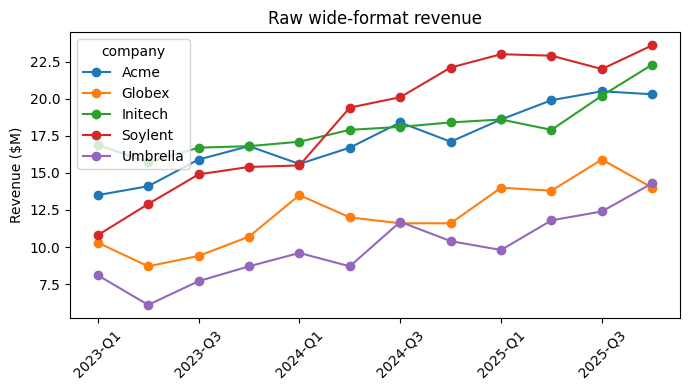

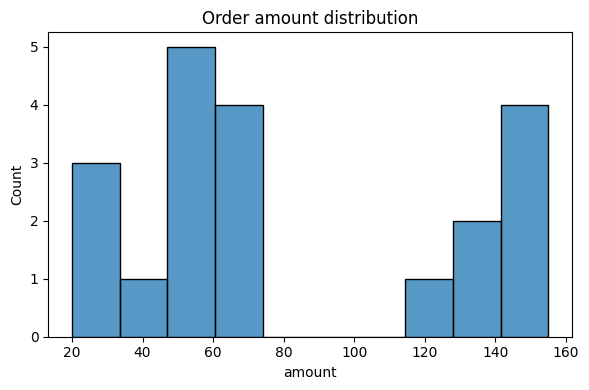

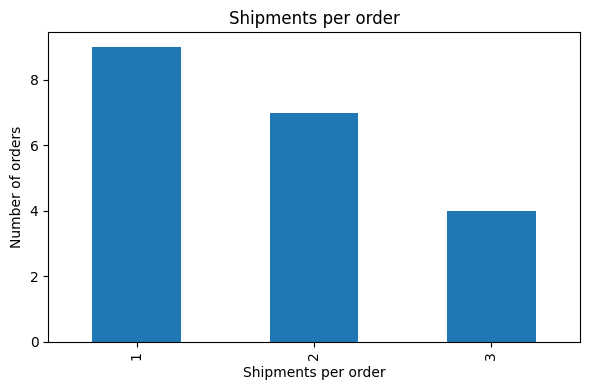

In [3]:
# Raw-form exploratory visualizations (before any tidying)
fig, ax = plt.subplots(figsize=(7, 4))
revenue_raw.set_index("company").T.plot(ax=ax, marker="o")
ax.set_title("Raw wide-format revenue")
ax.set_ylabel("Revenue ($M)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT / "step0_revenue_raw.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(orders["amount"], bins=10, ax=ax)
ax.set_title("Order amount distribution")
plt.tight_layout()
plt.savefig(OUT / "step0_orders_amount.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
shipments["order_id"].value_counts().value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Shipments per order")
ax.set_xlabel("Shipments per order")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.savefig(OUT / "step0_shipments_per_order.png", dpi=120)
plt.show()

## Task 1 — Reshape the revenue table (wide → long)

In [4]:
# Wide -> long: quarter was spread across column headers, which violates the first tidy rule.
revenue_tidy = revenue_raw.melt(id_vars="company", var_name="quarter", value_name="revenue")
print(revenue_tidy.shape)
revenue_tidy.head()

(60, 3)


,company,quarter,revenue
0,Acme,2023-Q1,13.5
1,Globex,2023-Q1,10.3
2,Initech,2023-Q1,16.9
3,Soylent,2023-Q1,10.8
4,Umbrella,2023-Q1,8.1


## Task 2 — Check key uniqueness before joining

In [5]:
print("orders: order_id unique?", orders["order_id"].is_unique,
      f"({orders['order_id'].nunique()}/{len(orders)})")
print("shipments: order_id unique?", shipments["order_id"].is_unique,
      f"({shipments['order_id'].nunique()}/{len(shipments)})")
# order_id is the primary key in orders but a foreign key in shipments 
# -> the join is one-to-many: each order row will be duplicated once per shipment
# that it has.

orders: order_id unique? True (20/20)
shipments: order_id unique? False (20/35)


## Task 3 — Join orders and shipments; compare the mean

In [6]:
orders_shipments = orders.merge(shipments, on="order_id", how="inner")
print("joined shape:", orders_shipments.shape)

mean_on_joined = orders_shipments.groupby("customer_id")["amount"].mean()
mean_orders_alone = orders.groupby("customer_id")["amount"].mean()

comparison = pd.DataFrame({
    "mean_orders_alone": mean_orders_alone,
    "mean_on_joined": mean_on_joined,
})
comparison["differs"] = (comparison["mean_orders_alone"] - comparison["mean_on_joined"]).abs() > 1e-9
comparison

joined shape: (35, 4)


,mean_orders_alone,mean_on_joined,differs
customer_id,,,
C100,38.00,38.000,False
C101,62.00,62.000,False
C102,105.00,105.000,False
C103,111.60,112.375,True
C104,33.00,33.000,False
C105,67.25,67.625,True
C106,59.50,62.250,True
C107,96.50,106.000,True


**`mean_orders_alone` is correct.** `amount` is a property of the order, not of the shipment. 

## Task 4 — Produce the analysis-ready table(s)

In [7]:
# revenue (company/quarter) and orders/shipments (order/customer) dont' share a
# common key, so we keep them as two separate tidy tables rather than forcing
# a cross-join that is essentially meaningless:

revenue_final = revenue_tidy.reset_index(drop=True)
orders_final = orders_shipments.rename(
    columns={"tracking": "tracking_number"}
).reset_index(drop=True)

revenue_final.to_csv(OUT / "revenue_analysis_ready.csv", index=False)
orders_final.to_csv(OUT / "orders_analysis_ready.csv", index=False)

revenue_final.head(), orders_final.head()

(    company  quarter  revenue
 0      Acme  2023-Q1     13.5
 1    Globex  2023-Q1     10.3
 2   Initech  2023-Q1     16.9
 3   Soylent  2023-Q1     10.8
 4  Umbrella  2023-Q1      8.1,
   order_id customer_id  amount tracking_number
 0    O1000        C106      26         O1000-1
 1    O1001        C105      48         O1001-1
 2    O1001        C105      48         O1001-2
 3    O1002        C103     155         O1002-1
 4    O1003        C100      38         O1003-1)

## Task 5 — Visualization: raw vs. tidy, side by side

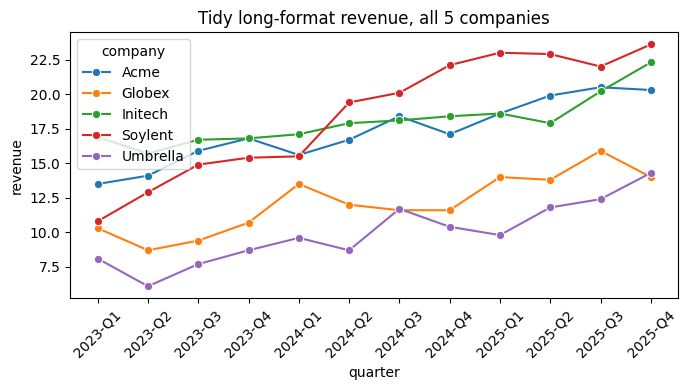

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=revenue_final, x="quarter", y="revenue", hue="company", marker="o", ax=ax)
ax.set_title("Tidy long-format revenue, all 5 companies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT / "step5_revenue_tidy.png", dpi=120)
plt.show()

**What got easier:** in Task 0 I had to transpose the wide table and set `company` as the index just to
plot quarters on the x-axis. With `quarter` as a column of its own, `sns.lineplot(..., hue="company")` works. It is one line, the 
legend is included, and it is able to handle any number of companies or quarters without any changes.